In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset.csv")

In [2]:
# Data Processing
import pandas as pd
import numpy as np

# Modelling
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint

# Tree Visualisation
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

In [3]:
# Referência: https://www.datacamp.com/tutorial/random-forests-classifier-python
X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [4]:
model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8563333333333333


In [5]:
# Calcula a probabilidade de vitoria
probabilities = model.predict_proba(X_test)
indice_vitoria = list(model.classes_).index(1)

# Extraindo a probabilidade de vitória em porcentagem
chances_vitoria = probabilities[:, indice_vitoria] * 100

# Exibindo os resultados
resultados = pd.DataFrame({
    "Resultado real": y_test.values,
    "Chance de vitória (%)": chances_vitoria,
    "Previsão do modelo": model.predict(X_test)
})

print(resultados)

      Resultado real  Chance de vitória (%)  Previsão do modelo
0                  1                   94.0                   1
1                  0                   64.0                   1
2                  0                   33.0                   0
3                  0                   21.0                   0
4                  0                   43.0                   0
...              ...                    ...                 ...
2995               1                   64.0                   1
2996               1                   66.0                   1
2997               0                    0.0                   0
2998               0                   34.0                   0
2999               0                   60.0                   1

[3000 rows x 3 columns]


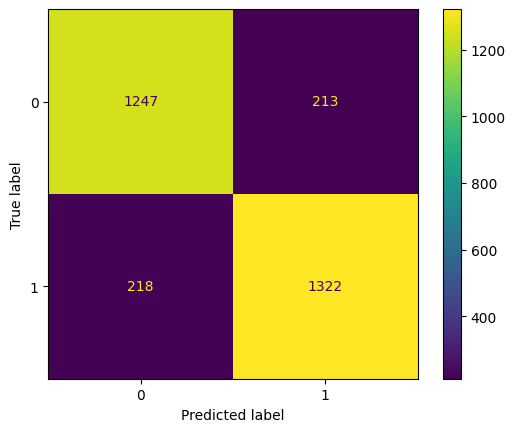

In [6]:
# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();